## This is a sanity Check for KARACHI

In [43]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as ticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [44]:
flexpartoutput_filename = '/jetfs/scratch/gbrack/flexpart_output/karachi_single_10d/grid_time_20150620120000.nc'
era5_filename = '/jetfs/scratch/gbrack/MSC/ERA_SHF_LHF_Pr.nc'

In [45]:
era = xr.open_dataset(era5_filename)
flexpart = xr.open_dataset(flexpartoutput_filename)
partoutput = xr.open_mfdataset('/jetfs/scratch/gbrack/flexpart_output/karachi_single_10d/partoutput_*.nc')

In [4]:
era_clean = era.rename({'valid_time': 'time'})
era_aligned = era_clean.reindex_like(flexpart)

In [5]:
partoutput

<xarray.Dataset> Size: 230MB
Dimensions:   (particle: 20000, time: 240)
Coordinates:
  * particle  (particle) int32 80kB 1 2 3 4 5 ... 19996 19997 19998 19999 20000
  * time      (time) datetime64[ns] 2kB 2015-06-20T11:00:00 ... 2015-06-10T12...
Data variables:
    lon       (particle, time) float32 19MB dask.array<chunksize=(20000, 1), meta=np.ndarray>
    lon_av    (particle, time) float32 19MB dask.array<chunksize=(20000, 1), meta=np.ndarray>
    lat       (particle, time) float32 19MB dask.array<chunksize=(20000, 1), meta=np.ndarray>
    lat_av    (particle, time) float32 19MB dask.array<chunksize=(20000, 1), meta=np.ndarray>
    z         (particle, time) float32 19MB dask.array<chunksize=(20000, 1), meta=np.ndarray>
    z_av      (particle, time) float32 19MB dask.array<chunksize=(20000, 1), meta=np.ndarray>
    pv        (particle, time) float32 19MB dask.array<chunksize=(20000, 1), meta=np.ndarray>
    pv_av     (particle, time) float32 19MB dask.array<chunksize=(20000, 1), meta=np.ndarray>
    sh        (particle, time) float32 19MB dask.array<chunksize=(20000, 1), meta=np.ndarray>
    sh_av     (particle, time) float32 19MB dask.array<chunksize=(20000, 1), meta=np.ndarray>
    T         (particle, time) float32 19MB dask.array<chunksize=(20000, 1), meta=np.ndarray>
    T_av      (particle, time) float32 19MB dask.array<chunksize=(20000, 1), meta=np.ndarray>
Attributes: (12/37)
    Conventions:            CF-1.6
    title:                  FLEXPART model output
    git:                    dace3af Mon Nov 24 10:17:47 2025 +0100
    source:                 Version 11.0 (2023-07-11) model output
    history:                2026-06-03 10:57 +0200  created by gbrack on jet1...
    references:             Stohl et al., Atmos. Chem. Phys., 2005, doi:10.51...
    ...                     ...
    ind_source:             1
    ind_receptor:           2
    mquasilag:              0
    nested_output:          2
    sfc_only:               0
    linit_cond:             2

In [6]:
initial_cond = partoutput.isel(time=-1)
end_cond = partoutput.isel(time=0)

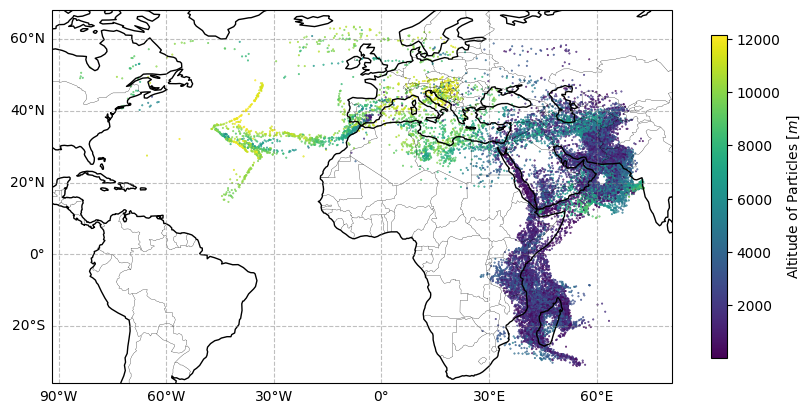

In [7]:
# lets look at the location of the particles at the first timestep

fig, ax = plt.subplots(1, 1, figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree()})

scatter = ax.scatter(initial_cond.lon_av, initial_cond.lat_av, s=0.2, transform=ccrs.PlateCarree(), c=initial_cond.z_av, cmap='viridis')

plt.colorbar(scatter, label=r'Altitude of Particles $[m]$', shrink=0.7)

gl = ax.gridlines(draw_labels=True, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, lw=0.2)

In [8]:
cp = 1004.6
Lv = 2501000
g = 9.81

MSE_initial = (cp * initial_cond.T_av) + (Lv * initial_cond.sh) + (g * initial_cond.z_av)
MSE_end = (cp * end_cond.T_av) + (Lv * end_cond.sh) + (g * end_cond.z_av)

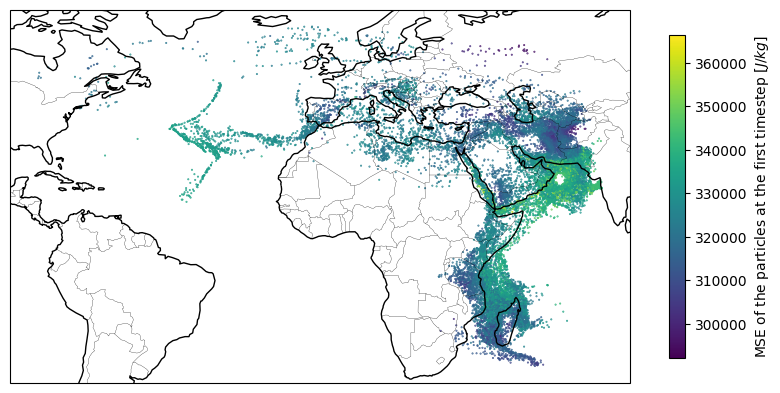

In [9]:
# let's look at the moist static energy of the particles at the first timestep

fig, ax = plt.subplots(1, 1, figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree()})

scatter = ax.scatter(initial_cond.lon_av, initial_cond.lat_av, s=0.2, transform=ccrs.PlateCarree(), c=MSE_initial, cmap='viridis')

plt.colorbar(scatter, label=r'MSE of the particles at the first timestep $[J/kg]$', shrink=0.7)

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, lw=0.2)

In [10]:
absolute_initial_MSE = MSE_initial.mean().values
print(f'Absolute initial MSE: {absolute_initial_MSE:.1f} J/kg')

Absolute initial MSE: 325484.6 J/kg


In [11]:
absolute_end_MSE = MSE_end.mean().values
print(f'Absolute final MSE: {absolute_end_MSE:.1f} J/kg')

Absolute final MSE: 347457.4 J/kg


In [12]:
lon_initial = initial_cond.lon_av
lat_initial = initial_cond.lat_av


print(f"West: {lon_initial.min().values - 5}")  # Minus 5 for the safety buffer
print(f"East: {lon_initial.max().values + 5}")
print(f"South: {lat_initial.min().values - 5}")
print(f"North: {lat_initial.max().values + 5}")

West: -4.949419837445021
East: 364.9942321777344
South: -36.16559028625488
North: 68.4924545288086


## Now let's get that $\Delta E$

In [13]:
residence_time = flexpart['spec001_mr'].sel(height=100).squeeze()
sshf = era_aligned['sshf']
slhf = era_aligned['slhf']

In [14]:
dt = 3600
rho = 1.2

In [15]:
#hourly_sh = (residence_time * (sshf * -1.0)) / (dt * 100 * rho)
#hourly_lh = (residence_time * (slhf * -1.0)) / (dt * 100 * rho)

hourly_sh = (residence_time * (sshf * -1.0)) / (dt * 100)
hourly_lh = (residence_time * (slhf * -1.0)) / (dt * 100)

In [16]:
total_sensible_added = hourly_sh.sum().values
total_latent_added = hourly_lh.sum().values

total_energy_added = total_sensible_added + total_latent_added

In [17]:
print(f"Target to find: {(absolute_end_MSE - absolute_initial_MSE):.1f}")
print(f"Total Sensible Heat added: {total_sensible_added:.1f} J/kg")
print(f"Total Latent Heat added:   {total_latent_added:.1f} J/kg")
print(f"---")
print(f"TOTAL SURFACE FORCING:     {total_energy_added:.1f} J/kg")

Target to find: 21972.8
Total Sensible Heat added: 11978.9 J/kg
Total Latent Heat added:   15734.5 J/kg
---
TOTAL SURFACE FORCING:     27713.4 J/kg


## Let's look at the $\Delta E$ distribution

In [18]:
# sum up energy uptake through time
total_sensible = hourly_sh.sum(dim='time')
total_latent = hourly_lh.sum(dim='time')

Text(0.5, 1.0, 'Total Sensible Heat Energy Accumulated over 10 Days')

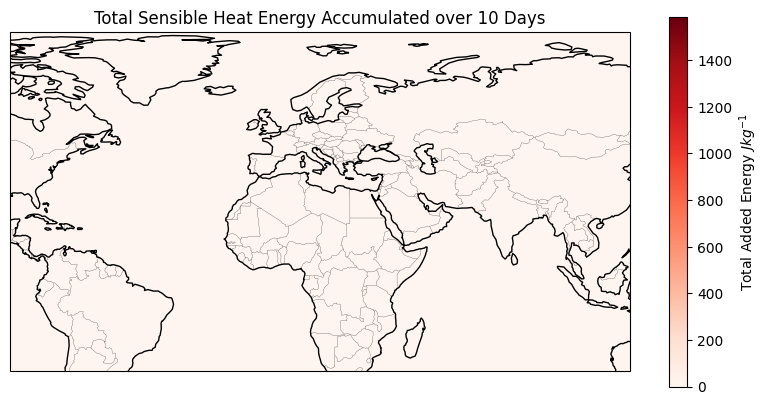

In [19]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree()})

max_energy = total_sensible.max().values

my_min = 0
my_max = np.round(max_energy, 0)

mesh = ax.pcolormesh(total_sensible.longitude,
                     total_sensible.latitude,
                     total_sensible,
                     transform=ccrs.PlateCarree(),
                     cmap='Reds',
                     vmin=my_min,
                     vmax=my_max
                    )

plt.colorbar(mesh, ax=ax, shrink=0.8, label=r'Total Added Energy $J kg^{-1}$')

ax.add_feature(cfeature.BORDERS, lw=0.2, alpha=0.8)
ax.add_feature(cfeature.COASTLINE)

ax.set_title('Total Sensible Heat Energy Accumulated over 10 Days')

Text(0.5, 1.0, 'Total Latent Heat Energy Accumulated over 10 Days')

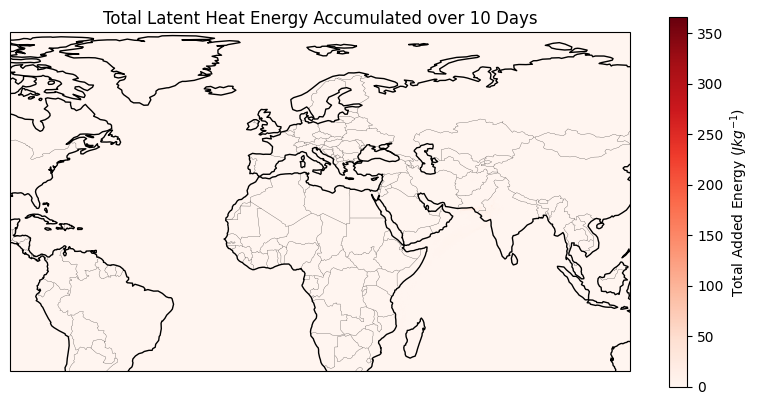

In [20]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree()}
                      )

max_energy = total_latent.max().values

my_min = 0
my_max = np.round(max_energy, 0)

mesh = ax.pcolormesh(total_latent.longitude,
                     total_latent.latitude,
                     total_latent,
                     transform=ccrs.PlateCarree(),
                     cmap='Reds',
                     vmin=my_min,
                     vmax=my_max
                    )

plt.colorbar(mesh, ax=ax, shrink=0.8, label=r'Total Added Energy ($J kg^{-1}$)')

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, lw=0.2, alpha=0.8)

ax.set_title('Total Latent Heat Energy Accumulated over 10 Days')

In [21]:
timeline_sh = hourly_sh.sum(dim=['latitude', 'longitude'])
timeline_lh = hourly_lh.sum(dim=['latitude', 'longitude'])

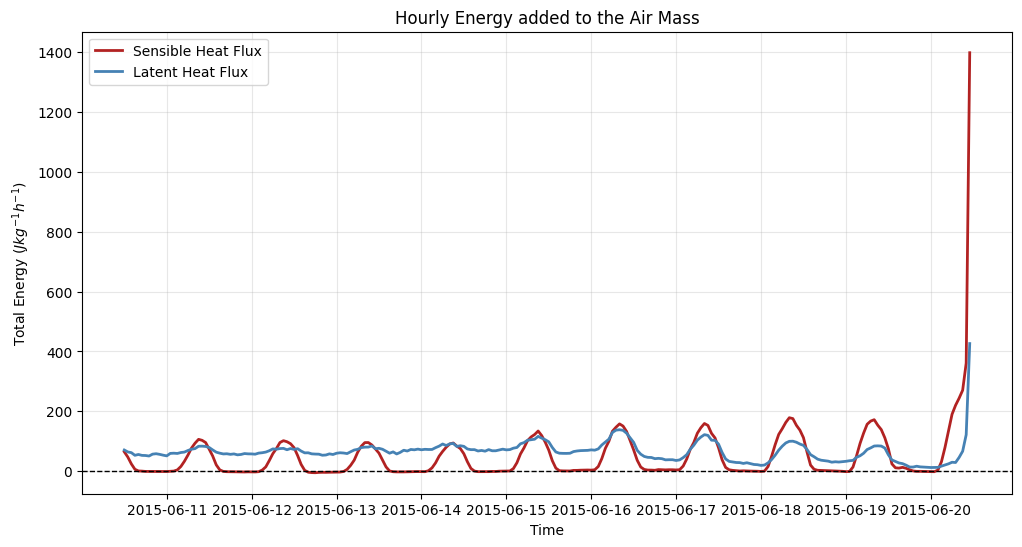

In [22]:
fig, ax = plt.subplots(1, 1, figsize=(12, 6))

ax.plot(timeline_sh.time,
        timeline_sh,
        color='firebrick',
        label='Sensible Heat Flux',
        lw=2
       )

ax.plot(timeline_lh.time,
        timeline_lh,
        color='steelblue',
        label='Latent Heat Flux',
        lw=2
       )

ax.axhline(0, c='k', lw='1', ls='--')

ax.set_title('Hourly Energy added to the Air Mass')
ax.set_ylabel(r'Total Energy ($J kg^{-1} h^{-1}$)')
ax.set_xlabel('Time')

ax.grid(True, alpha=0.3)
ax.legend()

## Okay let's do a little logarithmic scale to not ignore the starting point but also see other energy uptakes

Text(0.5, 1.0, 'Total Sensible Heat Energy Accumulated over 10 Days')

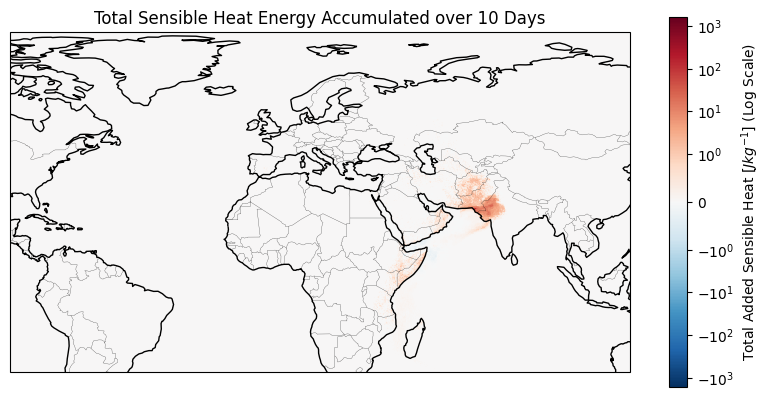

In [23]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree()}
                      )

mesh = ax.pcolormesh(total_sensible.longitude,
                     total_sensible.latitude,
                     total_sensible,
                     transform=ccrs.PlateCarree(),
                     cmap='RdBu_r',
                     norm=mcolors.SymLogNorm(linthresh=1.0,
                                             vmin=-total_sensible.max(),
                                             vmax=total_sensible.max(),
                                             base=10
                     )
)

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, lw=0.2, alpha=0.8)

plt.colorbar(mesh, ax=ax, shrink=0.8, label=r'Total Added Sensible Heat $[J kg^{-1}]$ (Log Scale)')
ax.set_title('Total Sensible Heat Energy Accumulated over 10 Days')

Text(0.5, 1.0, 'Total Latent Heat Energy Accumulated over 10 Days')

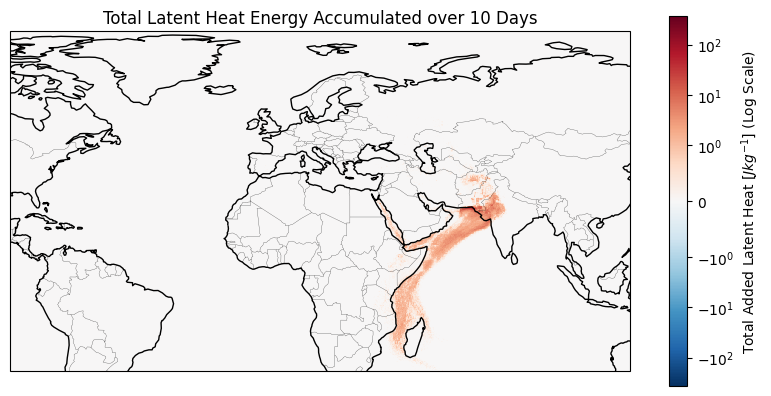

In [24]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree()}
                      )

mesh = ax.pcolormesh(total_latent.longitude,
                     total_latent.latitude,
                     total_latent,
                     transform=ccrs.PlateCarree(),
                     cmap='RdBu_r',
                     norm=mcolors.SymLogNorm(linthresh=1.0,
                                             vmin=-total_latent.max(),
                                             vmax=total_latent.max(),
                                             base=10
                     )
)

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, lw=0.2, alpha=0.8)

plt.colorbar(mesh, ax=ax, shrink=0.8, label=r'Total Added Latent Heat $[J kg^{-1}]$ (Log Scale)')
ax.set_title('Total Latent Heat Energy Accumulated over 10 Days')

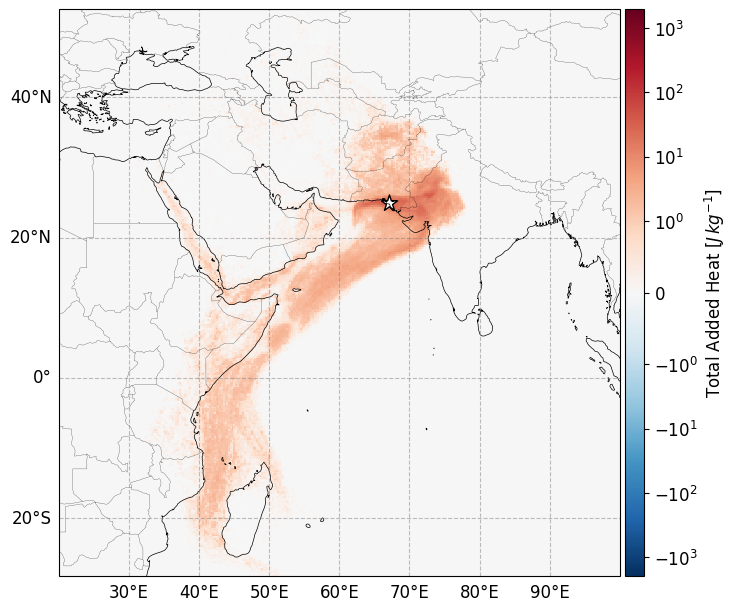

In [25]:
total_energy = total_latent + total_sensible

fig, ax = plt.subplots(1, 1, figsize=(7.5, 6), layout='compressed',
                       subplot_kw={'projection': ccrs.PlateCarree()},
                      )

mesh = ax.pcolormesh(total_energy.longitude,
                     total_energy.latitude,
                     total_energy,
                     transform=ccrs.PlateCarree(),
                     cmap='RdBu_r',
                     rasterized=True,
                     norm=mcolors.SymLogNorm(linthresh=1.0,
                                             vmin=-total_energy.max(),
                                             vmax=total_energy.max(),
                                             base=10
                     )
)
ax.scatter(67.1, 24.9,
           c='white',
           edgecolor='black',
           marker='*',
           s=150,
           label='Karachi, Pakistan'
          )

ax.add_feature(cfeature.COASTLINE.with_scale('50m'), lw=0.5)
ax.add_feature(cfeature.BORDERS.with_scale('50m'), lw=0.2, alpha=0.8)
ax.set_extent([20, 100, -22.5, 45])

gl = ax.gridlines(draw_labels=True, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.ylabel_style = {'size': 12}
gl.xlabel_style = {'size': 12}

cbar = plt.colorbar(mesh, ax=ax,
                    pad=0.01,
                    aspect=30,
                   )
cbar.set_label(r'Total Added Heat [$J \, kg^{-1}$]', fontsize=12)
cbar.ax.tick_params(labelsize=12)

#ax.set_title('Total Sensible and Latent Heat Energy Accumulated over 10 Days')
fig.savefig('prelim.pdf', dpi=150, bbox_inches='tight', pad_inches=0.02)

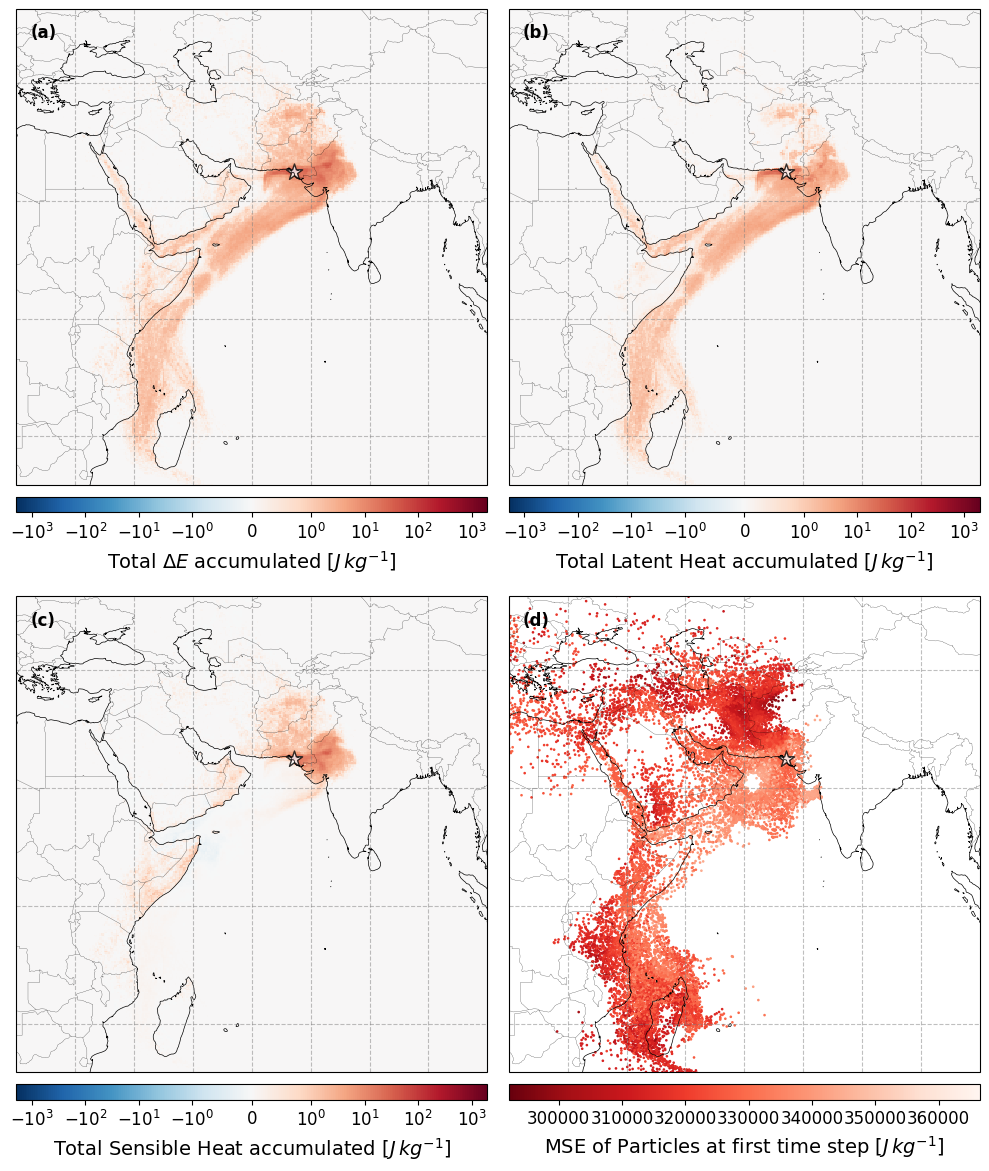

In [26]:
map_proj=ccrs.PlateCarree()

fig, axes = plt.subplots(2, 2, figsize=(10, 12), layout='tight',
                       subplot_kw={'projection': map_proj})

to_plot = [total_energy, total_latent, total_sensible, MSE_initial]
titles = [r'Total $\Delta E$ accumulated [$J \, kg^{-1}$]', r'Total Latent Heat accumulated [$J \, kg^{-1}$]', r'Total Sensible Heat accumulated [$J \, kg^{-1}$]', r'MSE of Particles at first time step [$J \, kg^{-1}$]']

for i in range(2):
    for o in range(2):
        ax = axes[i, o]
        if 2*i + o < 3:
            mesh = ax.pcolormesh(to_plot[2*i + o].longitude,
                                 to_plot[2*i + o].latitude,
                                 to_plot[2*i + o],
                                 transform=ccrs.PlateCarree(),
                                 cmap='RdBu_r',
                                 rasterized=True,
                                 norm=mcolors.SymLogNorm(linthresh=1.0,
                                                         vmin=-total_energy.max(),
                                                         vmax=total_energy.max(),
                                                         base=10
                                                         )
                                 )
            ax.set_extent([20, 100, -22.5, 45])
        else:
            mesh = ax.scatter(initial_cond.lon_av,
                              initial_cond.lat_av,
                              transform=map_proj,
                              cmap='Reds_r',
                              c=to_plot[2*i + o],
                              s=0.8,
                              )
            ax.set_extent([20, 100, -22.5, 45])
        
        ax.add_feature(cfeature.COASTLINE.with_scale('50m'), lw=0.5)
        ax.add_feature(cfeature.BORDERS.with_scale('50m'), lw=0.2, alpha=0.8)
        ax.set_extent([20, 100, -22.5, 45])
        subplot_label = f"({chr(ord('a') + 2*i + o)})" 
        axes[i][o].text(0.03, 0.97, subplot_label, 
                        transform=ax.transAxes, 
                        fontsize=12, 
                        fontweight='bold', 
                        va='top', 
                        ha='left')
        
        gl = ax.gridlines(draw_labels=False, color='gray', alpha=0.5, linestyle='--')
        gl.top_labels = False
        gl.right_labels = False
        gl.ylabel_style = {'size': 12}
        gl.xlabel_style = {'size': 12}
        
        ax.scatter(67.1, 24.9,
                   c='white',
                   edgecolor='black',
                   marker='*',
                   s=150,
                   label='Karachi, Pakistan',
                   alpha=0.8
                   )
        
        cbar = plt.colorbar(mesh, 
                            ax=ax, 
                            aspect=30, 
#                            shrink=0.75, 
                            location='bottom', 
                            pad=0.02,
                            label=titles[2*i + o]
                           )
        cbar.set_label(titles[2*i + o], fontsize=14)
        cbar.ax.tick_params(labelsize=12)
        
#plt.savefig('Karachi_new.pdf')

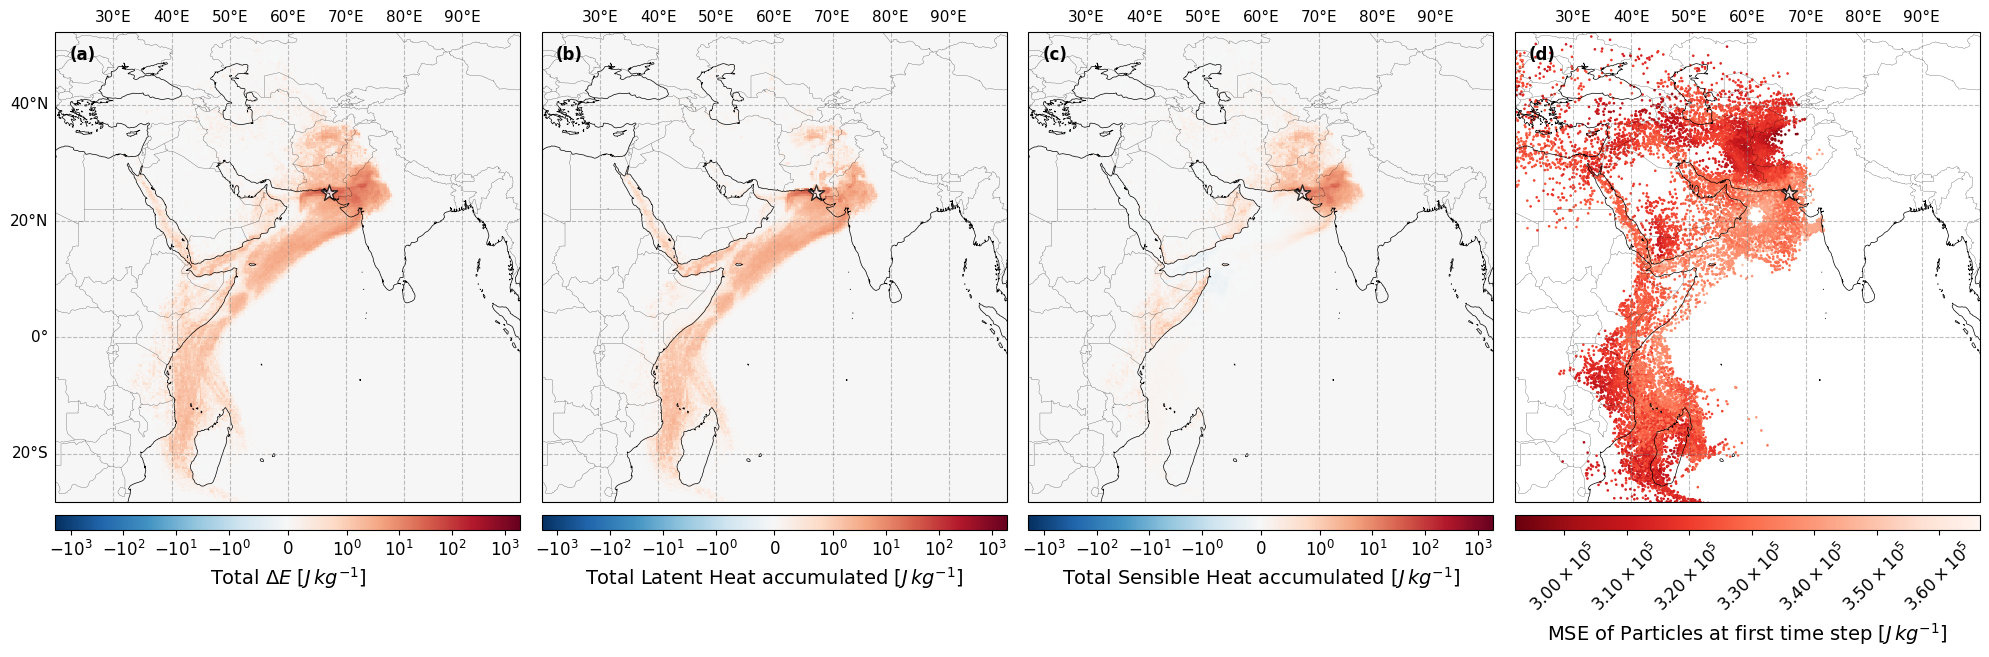

In [42]:
def fmt(x, pos):
    a, b = '{:.2e}'.format(x).split('e')
    b = int(b)
    return r'${} \times 10^{{{}}}$'.format(a, b)

map_proj=ccrs.PlateCarree()

fig, axes = plt.subplots(1, 4, figsize=(20, 7), layout='tight',
                       subplot_kw={'projection': map_proj})

to_plot = [total_energy, total_latent, total_sensible, MSE_initial]
titles = [r'Total $\Delta E$ [$J \, kg^{-1}$]', r'Total Latent Heat accumulated [$J \, kg^{-1}$]', r'Total Sensible Heat accumulated [$J \, kg^{-1}$]', r'MSE of Particles at first time step [$J \, kg^{-1}$]']

for i in range(4):
    ax = axes[i]
    if i < 3:
        mesh = ax.pcolormesh(to_plot[i].longitude,
                             to_plot[i].latitude,
                             to_plot[i],
                             transform=ccrs.PlateCarree(),
                             cmap='RdBu_r',
                             rasterized=True,
                             norm=mcolors.SymLogNorm(linthresh=1.0,
                                                     vmin=-total_energy.max(),
                                                     vmax=total_energy.max(),
                                                     base=10
                                                     )
                             )
        ax.set_extent([20, 100, -22.5, 45])
    else:
        mesh = ax.scatter(initial_cond.lon_av,
                          initial_cond.lat_av,
                          transform=map_proj,
                          cmap='Reds_r',
                          c=to_plot[i],
                          s=0.8,
                          )
        ax.set_extent([20, 100, -22.5, 45])

    ax.add_feature(cfeature.COASTLINE.with_scale('50m'), lw=0.5)
    ax.add_feature(cfeature.BORDERS.with_scale('50m'), lw=0.2, alpha=0.8)
    ax.set_extent([20, 100, -22.5, 45])
    subplot_label = f"({chr(ord('a') + i)})" 
    axes[i].text(0.03, 0.97, subplot_label, 
                 transform=ax.transAxes, 
                 fontsize=12, 
                 fontweight='bold', 
                 va='top', 
                 ha='left')

    gl = ax.gridlines(draw_labels=True, color='gray', alpha=0.5, linestyle='--')
    gl.bottom_labels = False
    gl.right_labels = False
    if i == 0:
        gl.left_labels = True
    else:
        gl.left_labels = False
    gl.ylabel_style = {'size': 11}
    gl.xlabel_style = {'size': 11}

    ax.scatter(67.1, 24.9,
               c='white',
               edgecolor='black',
               marker='*',
               s=150,
               label='Karachi, Pakistan',
               alpha=0.8
               )

    if i == 3:
        cbar = plt.colorbar(mesh, 
                            ax=ax, 
                            aspect=30, 
                            location='bottom', 
                            pad=0.02,
                            label=titles[i],
                            format=ticker.FuncFormatter(fmt),
                           )
        cbar.ax.tick_params(rotation=45)
    else:
        cbar = plt.colorbar(mesh, 
                        ax=ax, 
                        aspect=30, 
                        location='bottom', 
                        pad=0.02,
                        label=titles[i],
                       )
    cbar.set_label(titles[i], fontsize=14)
    cbar.ax.tick_params(labelsize=12)
    ax.xaxis.tick_top()

plt.savefig('Karachi_new.pdf')